# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Tumour-Board Briefing

### Scenario

You are the visualization engineer in the **3-D Imaging Lab at City General Hospital**. Tomorrow morning the
neuro-oncology **tumour board** (a neurosurgeon, a radiologist and an oncologist) will review a patient's head CT
(`unit3_ppt3_head_ct_phantom.csv`). The lab head forwards you four requests:

1. **IT department:** *"The new scanner protocol is 512 × 512 × 300 at 0.5 × 0.5 × 1.0 mm. How much storage per scan,
   and how many samples does one volume-rendered frame cost?"*
2. **Radiologist:** *"Show me the lesion in all three planes, at its centre, with the anatomy undistorted."*
3. **Neurosurgeon:** *"I need the tumour volume in mL — and I want to know how much that number depends on the
   threshold you picked."*
4. **Oncologist:** *"Your last 3-D render showed a beautiful skull and nothing else. I need to see the tumour and its
   relation to the ventricles."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your
own words. The ground-truth `labels` array may be used **only to evaluate** your results, never to find the tumour.

## Part 0 — Setup (given)

Run this cell as-is. It loads the volume `vol[z, y, x]`, the evaluation-only `labels`, the voxel spacing, and two
helpers: `make_tf(points)` builds a transfer function from `(hu, (r, g, b), alpha)` control points, and
`render(volume, tf, axis)` ray-casts the volume with front-to-back compositing (resampled at 2× density).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

ct = pd.read_csv("unit3_ppt3_head_ct_phantom.csv")
NZ, NY, NX = ct.z.max() + 1, ct.y.max() + 1, ct.x.max() + 1
vol = ct.intensity_hu.values.reshape(NZ, NY, NX)        # V[z, y, x]  (z = feet->head, y = front->back, x = left->right)
labels = ct.label.values.reshape(NZ, NY, NX)            # ground truth: 0 air, 1 scalp, 2 bone, 3 brain, 4 CSF, 5 tumour
SPACING = (4.0, 3.0, 3.0)                               # voxel size in mm along (z, y, x)
VOXEL_MM3 = np.prod(SPACING)
ASPECT = SPACING[0] / SPACING[2]                        # use when z is on a screen axis

def make_tf(points):
    # points: list of (hu, (r, g, b), alpha) control points -> transfer function T(s) -> (C, alpha)
    hu = np.array([p[0] for p in points], float)
    rgb = np.array([p[1] for p in points], float)
    alpha = np.array([p[2] for p in points], float)
    def tf(s):
        c = np.stack([np.interp(s, hu, rgb[:, k]) for k in range(3)], axis=-1)
        return c, np.interp(s, hu, alpha)
    return tf

def render(volume, tf, axis=1, upsample=2):
    # Orthographic ray casting with front-to-back compositing; rays travel along `axis`.
    # upsample=2 resamples the volume trilinearly at twice the density (smoother, fewer aliasing artifacts).
    v = ndimage.zoom(volume.astype(float), upsample, order=1) if upsample > 1 else volume
    v = np.moveaxis(v, axis, 0)
    C = np.zeros(v.shape[1:] + (3,)); A = np.zeros(v.shape[1:])
    for sample in v:                                    # one sample per voxel step along every ray at once
        c, a = tf(sample)
        C += ((1 - A) * a)[..., None] * c
        A += (1 - A) * a
    return C, A

print(f"vol {vol.shape} (z, y, x), voxel {SPACING} mm, {VOXEL_MM3:.0f} mm^3 per voxel")

vol (48, 64, 64) (z, y, x), voxel (4.0, 3.0, 3.0) mm, 36 mm^3 per voxel


## Task 1 — The IT Department's Numbers (Request #1)

**Real-world usage:** PACS storage and GPU sizing for 3-D workstations are budgeted from exactly these figures.

**Why this technique:** Voxel count = Nx·Ny·Nz (Slides 7, 12); each ray samples the volume at successive positions
(Slide 22), so one frame costs ≈ rays × samples per ray; early ray termination skips samples once α_acc → 1
(Slide 27).

**TODO:**
1. Number of voxels in a 512 × 512 × 300 scan, and its size in MB at 16 bits per voxel.
2. Physical size of the scanned region in mm, and the volume of one voxel in mm³ (0.5 × 0.5 × 1.0 mm).
3. Samples needed for ONE front-view rendered frame (one ray per x–z pixel, one sample per voxel step in y), and
   for a 360° rotation video of 120 frames.
4. If early ray termination stops rays after 35% of their samples on average, how many samples does the 120-frame
   video need instead?

In [2]:
NX_, NY_, NZ_ = 512, 512, 300          # new protocol: x, y, z
SP_ = (0.5, 0.5, 1.0)                  # mm along x, y, z

# TODO 1
n_voxels = NX_ * NY_ * NZ_
scan_mb = n_voxels * 2 / 1024**2       # 16 bits = 2 bytes per voxel

# TODO 2
extent_mm = (NX_ * SP_[0], NY_ * SP_[1], NZ_ * SP_[2])          # (x, y, z) in mm
voxel_mm3 = SP_[0] * SP_[1] * SP_[2]

# TODO 3: front view = rays along y, one ray per (x, z) pixel, one sample per voxel step in y
samples_per_frame = (NX_ * NZ_) * NY_
samples_video = samples_per_frame * 120

# TODO 4: early ray termination -> rays stop after 35% of their samples on average
samples_video_ert = samples_video * 0.35

print(f"{n_voxels:,} voxels = {scan_mb:.1f} MB | extent {extent_mm} mm | voxel {voxel_mm3} mm^3")
print(f"samples/frame {samples_per_frame:,} | 120 frames {samples_video:,} | with early termination {samples_video_ert:,.0f}")

print(f"\nrays per frame: {NX_*NZ_:,}  x  {NY_} samples per ray")
print(f"one frame touches every voxel once: samples/frame == n_voxels -> {samples_per_frame == n_voxels}")
print(f"early termination saves {samples_video - samples_video_ert:,.0f} samples ({1-0.35:.0%})")
print(f"the render helper used below resamples at 2x density -> 2^3 = 8x the samples of the raw grid")
print(f"\nfor comparison, this phantom: {vol.size:,} voxels of {VOXEL_MM3:.0f} mm^3 "
      f"-> the new protocol's voxels are {VOXEL_MM3/voxel_mm3:.0f}x smaller")


78,643,200 voxels = 150.0 MB | extent (256.0, 256.0, 300.0) mm | voxel 0.25 mm^3
samples/frame 78,643,200 | 120 frames 9,437,184,000 | with early termination 3,303,014,400

rays per frame: 153,600  x  512 samples per ray
one frame touches every voxel once: samples/frame == n_voxels -> True
early termination saves 6,134,169,600 samples (65%)
the render helper used below resamples at 2x density -> 2^3 = 8x the samples of the raw grid

for comparison, this phantom: 196,608 voxels of 36 mm^3 -> the new protocol's voxels are 144x smaller


**Reflection:** The new protocol has *anisotropic* voxels (0.5 × 0.5 × 1.0 mm). What two things would go wrong in the
radiologist's coronal and sagittal views if the software ignored that (Slides 8–10)?

_Your answer:_

With voxels of 0.5 × 0.5 × **1.0** mm, each step in z is **twice** as long as a step in x or y. If the software drew every
voxel as a square pixel:

1. **The anatomy would be squashed.** In the coronal and sagittal views, which both contain z, the head would appear
   **half as tall** as it really is: a round lesion becomes a flat ellipse, angles between structures change, and any
   distance a radiologist measures on screen in the vertical direction is off by a factor of 2. The fix is the voxel
   aspect ratio — `aspect = 1.0 / 0.5 = 2` for this protocol (our phantom uses 4 mm / 3 mm = **1.33**).
2. **The two in-plane directions would not have equal detail.** Even with the correct aspect, z is sampled half as
   finely, so coronal/sagittal reconstructions are blurrier vertically and edges that are oblique to z show
   **stair-stepping**; a structure thinner than ~1 mm in z can fall between slices or be averaged into its neighbours
   (**partial volume**). Ignoring this would make an artefact look like anatomy.

A third, quantitative consequence follows from the same mistake: any volume computed as *voxel count × voxel volume*
would be wrong if the software assumed isotropic voxels — here the true voxel volume is **0.25 mm³**, not 0.125 mm³.

## Task 2 — Find the Lesion and Show It in Three Planes (Request #2)

**Real-world usage:** Every radiology workstation opens on a 3-plane MPR with linked cross-hairs.

**Why this technique:** **Orthogonal slices / MPR** give complementary views of the same structure (Slides 15–17);
a **window/level** setting is the slice-display transfer function; the correct **voxel aspect ratio** keeps anatomy
undistorted (Slide 9).

**TODO:**
1. Find the lesion *without* `labels`: take voxels with 55 < HU < 90 that lie **inside the brain** — use
   `inside = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)` and erode it 3 times
   (`ndimage.binary_erosion(..., iterations=3)`) to avoid the partial-volume shell under the skull.
2. Keep the largest connected component (`ndimage.label`) and compute its centroid (z, y, x) as integers.
3. Plot axial, coronal and sagittal slices through that centroid with cross-hairs, a brain window (W = 80, L = 40),
   and `aspect=ASPECT` for the two views that contain z.
4. Evaluation only: print how far (in mm) your centroid is from the centroid of `labels == 5`.

431 candidate voxels in 1 components; largest = 431 voxels (next largest 0)
lesion centroid (z, y, x) = (28, 40, 41)


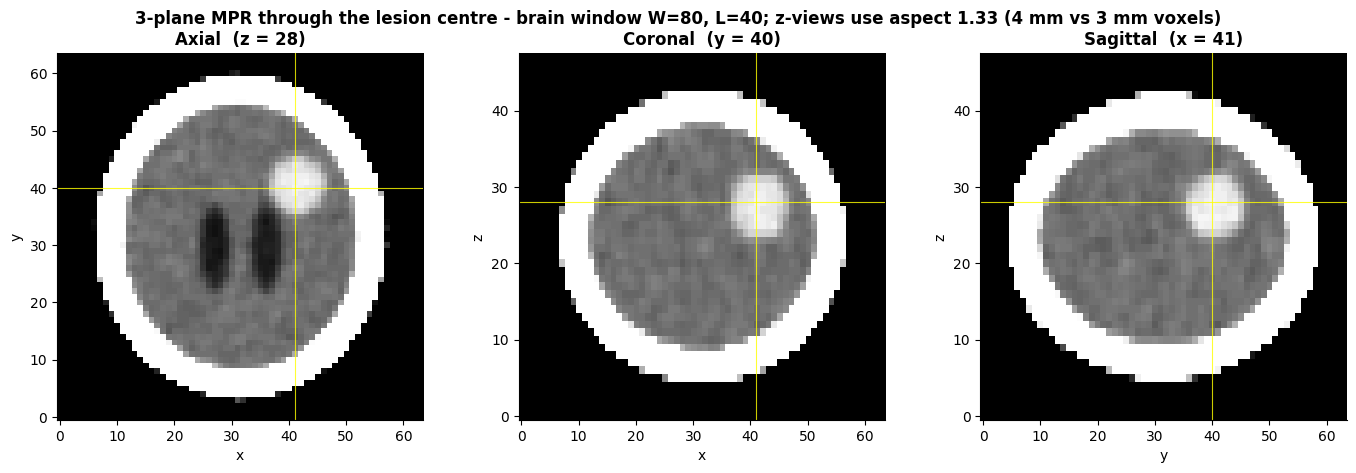

ground-truth centroid (27.5, 40.5, 41.5) -> my centroid is 2.92 mm away
WITHOUT erosion: 1,723 candidate voxels in 720 components (1,292 extra voxels, almost all in the shell under the skull)
tissue labels of those extra voxels: {'brain': 1292}


In [3]:
def window(a, W, L):
    return np.clip((a - (L - W / 2)) / W, 0, 1)

# TODO 1: lesion-range voxels strictly inside the skull, away from the partial-volume shell
bone = vol > 300
inside = ndimage.binary_fill_holes(bone) & ~bone
inside = ndimage.binary_erosion(inside, iterations=3)
candidates = (vol > 55) & (vol < 90) & inside

# TODO 2: largest connected component + its centroid
lab, n = ndimage.label(candidates)
sizes = ndimage.sum(candidates, lab, index=np.arange(1, n + 1))
lesion = lab == (np.argmax(sizes) + 1)
cz, cy, cx = (int(round(v)) for v in ndimage.center_of_mass(lesion))
print(f"{candidates.sum():,} candidate voxels in {n} components; largest = {int(sizes.max()):,} voxels "
      f"(next largest {int(np.sort(sizes)[-2]) if n > 1 else 0:,})")
print(f"lesion centroid (z, y, x) = ({cz}, {cy}, {cx})")

# TODO 3: axial / coronal / sagittal through the centroid, brain window W=80 L=40
W, L = 80, 40
views = [
    ("Axial  (z = %d)" % cz,    vol[cz, :, :], (cx, cy), 1.0,    "x", "y"),
    ("Coronal  (y = %d)" % cy,  vol[:, cy, :], (cx, cz), ASPECT, "x", "z"),
    ("Sagittal  (x = %d)" % cx, vol[:, :, cx], (cy, cz), ASPECT, "y", "z"),
]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
for ax, (title, sl, (hx, hy), asp, xl, yl) in zip(axes, views):
    ax.imshow(window(sl, W, L), cmap="gray", origin="lower", aspect=asp)
    ax.axhline(hy, color="yellow", lw=0.8, alpha=0.8); ax.axvline(hx, color="yellow", lw=0.8, alpha=0.8)
    ax.set_title(title, fontweight="bold"); ax.set_xlabel(xl); ax.set_ylabel(yl)
fig.suptitle(f"3-plane MPR through the lesion centre - brain window W={W}, L={L}; "
             f"z-views use aspect {ASPECT:.2f} (4 mm vs 3 mm voxels)", fontweight="bold")
plt.tight_layout(); plt.show()

# TODO 4 (evaluation only)
tz, ty, tx = ndimage.center_of_mass(labels == 5)
err_mm = np.sqrt(((cz - tz) * SPACING[0])**2 + ((cy - ty) * SPACING[1])**2 + ((cx - tx) * SPACING[2])**2)
print(f"ground-truth centroid ({tz:.1f}, {ty:.1f}, {tx:.1f}) -> my centroid is {err_mm:.2f} mm away")

# why the erosion matters: rerun step 1 without it
raw_inside = ndimage.binary_fill_holes(bone) & ~bone
raw_cand = (vol > 55) & (vol < 90) & raw_inside
rl, rn = ndimage.label(raw_cand)
print(f"WITHOUT erosion: {raw_cand.sum():,} candidate voxels in {rn} components "
      f"({raw_cand.sum() - candidates.sum():,} extra voxels, almost all in the shell under the skull)")
print(f"tissue labels of those extra voxels: "
      f"{pd.Series(labels[raw_cand & ~candidates]).map({0:'air',1:'scalp',2:'bone',3:'brain',4:'CSF',5:'tumour'}).value_counts().to_dict()}")


**Reflection:** Why did you need the erosion step? Explain in terms of the **partial-volume effect** and the
overlapping intensity ranges the lecture lists as a transfer-function challenge (Slide 28).

_Your answer:_

**Because the tumour's intensity range is shared by voxels that are not tumour.** Without erosion, step 1 finds
**1,723** candidate voxels in **720** separate components; with erosion it finds **431** voxels in exactly **one**
component. All **1,292** extra voxels are labelled *brain* and they sit in the thin shell just under the skull.

That shell is the **partial-volume effect**. A voxel on the bone–brain boundary contains part bone (~700 HU) and part
brain (~35 HU), so the scanner records an average. Somewhere in that blend lies every value between the two — including
the 55–90 HU band the tumour occupies (its own voxels run ~52–76 HU). So in intensity space the boundary and the lesion
are **indistinguishable**, which is exactly the **overlapping intensity ranges** problem the lecture lists as a
transfer-function challenge (Slide 28): a rule that looks only at the value at one voxel cannot separate two structures
that share values.

Erosion works because it uses **geometry instead of intensity**: peeling 3 voxels (9 mm here) off the inside of the
skull removes the region where blending can happen, while the deep lesion is untouched. The trade-off is real: a tumour
that *touched* the skull would be eroded away too, so this pipeline would silently miss a peripheral lesion.

## Task 3 — Tumour Volume and Its Threshold Sensitivity (Request #3)

**Real-world usage:** Tumour volume drives treatment decisions and response assessment, so its uncertainty must be
reported.

**Why this technique:** An **isosurface/segmentation at threshold c** defines the structure — and *the chosen c
strongly influences the resulting geometry* (Slides 19–20, 31–32).

**TODO:**
1. For c in `[45, 50, 55, 60, 65, 70]`, grow the region `vol > c` from your lesion centre (connected component
   containing `(cz, cy, cx)`).
2. For each c, record the voxel count, the volume in mL (`voxels * VOXEL_MM3 / 1000`), and — evaluation only — the
   Dice overlap with `labels == 5`.
3. Plot volume (mL) vs. threshold, and mark the threshold with the best Dice.
4. Print the range of volumes you would report to the surgeon.

,threshold_hu,voxels,volume_ml,dice_vs_truth
0,45,535,19.260,0.929
1,50,464,16.704,0.994
2,55,431,15.516,0.963
3,60,350,12.600,0.860
4,65,273,9.828,0.741
5,70,170,6.120,0.536


ground-truth tumour: 464 voxels = 16.70 mL


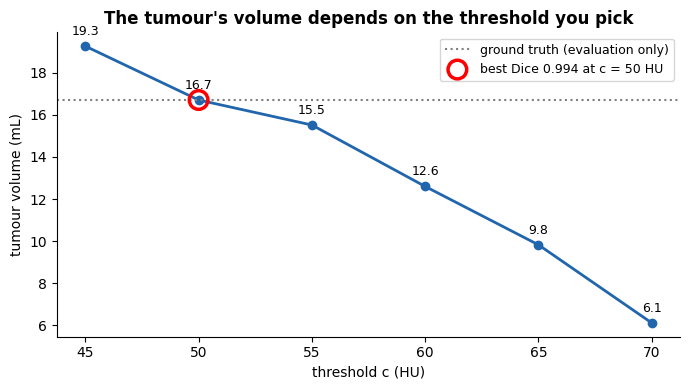

lesion median 68.0 HU, surrounding brain median 39.0 HU -> half-way threshold 53.5 HU
Report to the surgeon: 15.5 - 16.7 mL  (thresholds within +/-5 HU of 54 HU: [50, 55])
Across ALL six thresholds the 'volume' ranges 6.1 - 19.3 mL - a 3.1x spread from a 25 HU change in c.
(evaluation only) best Dice 0.994 at 50 HU -> 16.7 mL; truth 16.7 mL


In [4]:
truth = labels == 5
rows = []
# TODO 1 & 2
for c in [45, 50, 55, 60, 65, 70]:
    lab_c, _ = ndimage.label(vol > c)
    k = lab_c[cz, cy, cx]
    region = (lab_c == k) if k > 0 else np.zeros_like(truth)
    nvox = int(region.sum())
    dice = 2 * (region & truth).sum() / (region.sum() + truth.sum())
    rows.append({"threshold_hu": c, "voxels": nvox, "volume_ml": nvox * VOXEL_MM3 / 1000,
                 "dice_vs_truth": round(float(dice), 3)})

table = pd.DataFrame(rows)
display(table)
print(f"ground-truth tumour: {truth.sum():,} voxels = {truth.sum() * VOXEL_MM3 / 1000:.2f} mL")

# TODO 3
best = table.loc[table.dice_vs_truth.idxmax()]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(table.threshold_hu, table.volume_ml, "-o", color="#2166ac", lw=2)
ax.axhline(truth.sum() * VOXEL_MM3 / 1000, color="grey", ls=":", label="ground truth (evaluation only)")
ax.scatter([best.threshold_hu], [best.volume_ml], s=180, facecolor="none", edgecolor="red", lw=2.5,
           zorder=5, label=f"best Dice {best.dice_vs_truth:.3f} at c = {best.threshold_hu:.0f} HU")
for _, r in table.iterrows():
    ax.annotate(f"{r.volume_ml:.1f}", (r.threshold_hu, r.volume_ml), textcoords="offset points",
                xytext=(0, 8), ha="center", fontsize=9)
ax.set_xlabel("threshold c (HU)"); ax.set_ylabel("tumour volume (mL)")
ax.set_title("The tumour's volume depends on the threshold you pick", fontweight="bold")
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

# TODO 4 -- choose the reporting range WITHOUT labels: the lesion's edge is where intensity is
# half-way between the lesion itself and the brain immediately around it (a half-maximum boundary)
ring = ndimage.binary_dilation(lesion, iterations=2) & ~lesion & inside
tum_med, bg_med = np.median(vol[lesion]), np.median(vol[ring])
c_mid = (tum_med + bg_med) / 2
near = table[(table.threshold_hu - c_mid).abs() <= 5]
lo, hi = near.volume_ml.min(), near.volume_ml.max()
print(f"lesion median {tum_med:.1f} HU, surrounding brain median {bg_med:.1f} HU -> half-way threshold {c_mid:.1f} HU")
print(f"Report to the surgeon: {lo:.1f} - {hi:.1f} mL  "
      f"(thresholds within +/-5 HU of {c_mid:.0f} HU: {near.threshold_hu.tolist()})")
print(f"Across ALL six thresholds the 'volume' ranges {table.volume_ml.min():.1f} - {table.volume_ml.max():.1f} mL "
      f"- a {table.volume_ml.max()/table.volume_ml.min():.1f}x spread from a 25 HU change in c.")
print(f"(evaluation only) best Dice {best.dice_vs_truth:.3f} at {best.threshold_hu:.0f} HU -> {best.volume_ml:.1f} mL; "
      f"truth {truth.sum() * VOXEL_MM3 / 1000:.1f} mL")


**Reflection:** In real life there is no ground-truth label. How would you choose and justify c for the tumour
board, and how would you *visualize* the uncertainty so the surgeon doesn't treat a single number as exact?

_Your answer:_

**Choosing c without labels.** I picked the threshold from the image itself: the lesion's edge is where intensity is
**half-way** between the lesion and the brain around it — a half-maximum boundary. The lesion's median is **68 HU** and
the 2-voxel ring of surrounding brain has a median of **39 HU**, so **c ≈ 53.5 HU**. I would report the thresholds within
±5 HU of that (50 and 55 HU), which gives **15.5–16.7 mL**. (Evaluation only: the ground truth is 16.7 mL, inside that
range, and the best Dice, 0.994, is at 50 HU — but the choice above was made without looking.) The justification to the
board is that the rule is stated *before* seeing the answer and is reproducible on the next scan.

**Why the number must not be quoted alone.** Over the full sweep the "volume" falls from **19.3 mL at 45 HU to 6.1 mL at
70 HU — a 3.1x spread for a 25 HU change in c**. A single number like "16.7 mL" hides that it is a *function* of an
analyst's choice.

**How I would show the uncertainty:**
- **Nested contours on the MPR slices** — draw the boundary at 50, 55 and 60 HU as three thin outlines on the same slice.
  Where they are close together, the edge is sharp and well-defined; where they spread apart, the edge is uncertain. The
  surgeon sees *where* the uncertainty is, not just how much.
- **The volume-vs-threshold curve** (as in Task 3) with the defensible band shaded, so the sensitivity is visible.
- **A range in the text**, e.g. "≈ 16 mL (15.5–16.7 mL at defensible thresholds)", never a bare number with three
  significant figures.

For follow-up scans the same rule must be reused unchanged; otherwise a change in c will look like tumour growth or
shrinkage.

## Task 4 — A 3-D Render That Shows the Tumour (Request #4)

**Real-world usage:** Pre-operative 3-D views show a lesion in context with critical structures (here the ventricles).

**Why this technique:** **Direct volume rendering** with a designed **transfer function** — colour to *identify*
materials, opacity to *reveal or suppress* them (Slides 21–27); occlusion is the main enemy (Slide 28).

**TODO:**
1. Render the given `bone_tf` (front view, `axis=1`) — this is the "beautiful skull" the oncologist complained about.
2. Design your own `tumour_tf` with `make_tf([...])` so that: air and soft tissue are fully transparent, bone is
   *almost* transparent (α ≤ 0.01, still gives context), CSF (≈ 5–20 HU) is blue and faint, and the tumour range
   is red. Remember that opacity **accumulates over every sample along a ray**: a thick structure with α ≈ 0.1
   per sample becomes nearly opaque, while a thin one stays faint — use that to your advantage.
3. Render your TF from the front (`axis=1`) **and** from above (`axis=0`), side by side with the bone render.
4. Give the figure a conclusion-style title.

Given bone TF - front view                 mean accumulated opacity 0.528, max 1.000


My tumour TF - front view (rays along y)   mean accumulated opacity 0.180, max 0.885


My tumour TF - top view (rays along z)     mean accumulated opacity 0.148, max 0.827


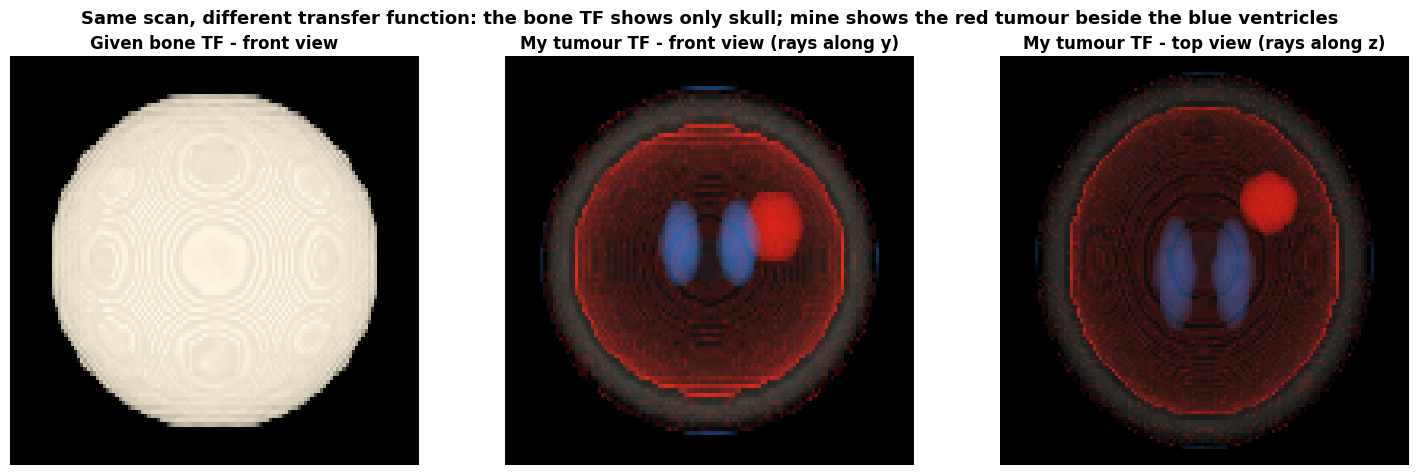

In [5]:
bone_tf = make_tf([(-1000, (0, 0, 0), 0), (200, (0, 0, 0), 0), (400, (1, 0.95, 0.85), 0.3), (1500, (1, 1, 1), 0.6)])

# TODO 2: your transfer function
BLUE, RED, IVORY = (0.25, 0.55, 1.0), (1.0, 0.12, 0.08), (1.0, 0.95, 0.85)
tumour_tf = make_tf([
    (-1000, (0, 0, 0), 0.0),     # air: invisible
    (0,     BLUE,      0.0),
    (5,     BLUE,      0.03),    # CSF ~5-20 HU: blue, faint per sample -> only thick CSF (ventricles) builds up
    (20,    BLUE,      0.03),
    (25,    (0, 0, 0), 0.0),     # brain / soft tissue ~25-45 HU: fully transparent
    (50,    (0, 0, 0), 0.0),
    (58,    RED,       0.08),    # tumour ~52-76 HU: red; ~16 samples through it -> 1-0.92^16 = 74% opaque
    (78,    RED,       0.08),
    (90,    (0, 0, 0), 0.0),     # above the tumour range: back to transparent
    (300,   (0, 0, 0), 0.0),
    (400,   IVORY,     0.004),   # bone: almost transparent, just enough to hint at the skull outline
    (1500,  IVORY,     0.008),
])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
# TODO 1 & 3: bone render | your TF front view | your TF top view
panels = [
    (bone_tf,   1, "Given bone TF - front view"),
    (tumour_tf, 1, "My tumour TF - front view (rays along y)"),
    (tumour_tf, 0, "My tumour TF - top view (rays along z)"),
]
for ax, (tf, axis, title) in zip(axes, panels):
    C, A = render(vol, tf, axis=axis)
    img = np.clip(C, 0, 1)
    asp = ASPECT if axis == 1 else 1.0          # front view keeps z on screen -> correct it
    ax.imshow(img, origin="lower", aspect=asp)
    ax.set_title(title, fontweight="bold"); ax.axis("off")
    print(f"{title:<42} mean accumulated opacity {A.mean():.3f}, max {A.max():.3f}")

# TODO 4: suptitle
fig.suptitle("Same scan, different transfer function: the bone TF shows only skull; "
             "mine shows the red tumour beside the blue ventricles", fontsize=13, fontweight="bold")
plt.tight_layout(); plt.show()


**Reflection:** Your tumour TF probably also lights up a faint red rim just inside the skull. Which volume-rendering
challenge from Slide 28 causes it? Name one technique from this lecture (hint: Slides 31–32) that would remove it,
and explain why a transfer function alone cannot.

_Your answer:_

The rim is the **partial-volume effect** combined with the **overlapping value ranges** challenge (Slide 28). Voxels on
the skull's inner surface blend bone and brain into values that land in the tumour's 52–76 HU band, so my transfer
function — which correctly paints that band red — paints them red too. Even after narrowing the red band to 58–78 HU and
lowering its per-sample opacity to 0.08, a faint red shell remains; it shows up face-on as a dim red haze across the
whole head in both views.

**Fix: segmentation** (Slides 31–32). Label the tumour first — e.g. the connected component grown from the lesion centre
in Task 3, or the eroded brain mask from Task 2 — and then render only that label in red (or multiply the transfer
function's opacity by the mask). The shell voxels have the same values as the tumour but are not connected to it and are
outside the eroded brain, so a label volume excludes them.

**Why a transfer function alone cannot:** a 1-D transfer function is a mapping **T(s) → (C, α)** from the *value*
alone. Two voxels with the same HU must receive the same colour and opacity, wherever they are. Telling the rim from the
tumour requires information that is **not in the value** — position, connectivity, distance from the skull — and that
is precisely what segmentation adds. (A 2-D transfer function using gradient magnitude can suppress boundaries
partially, but that is still a local cue, not an anatomical label.)

## Task 5 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the tumour board covering the whole notebook. It should:
- State where the lesion is and its volume **as a range** (Task 3), in plain language.
- Recommend which **one** view to open the meeting with (MPR, segmentation overlay, or the 3-D render) and justify
  it with at least one lecture idea (occlusion, slicing exposes internal structure, transfer-function overlap,
  segmentation enables measurement).
- Name one limitation of the 3-D render the board should keep in mind.

_Your final note here:_

**Note to the tumour board**

**Where and how big.** There is a single, well-defined lesion in the upper half of the brain, set off to one side and
toward the back (centre at slice z = 28 of 48, y = 40, x = 41 of 64), lying just beside and behind the ventricle on the
same side. It is roughly 3 cm across. Its volume is **about 16 mL — between 15.5 and 16.7 mL** depending on exactly where
its edge is drawn; please treat it as a range, because a stricter or looser edge definition moves the figure anywhere
from 6 to 19 mL.

**Open with the 3-plane MPR with the lesion outline overlaid.** Slicing **exposes internal structure without
occlusion**: every pixel on an MPR is a real measured value, so the radiologist can judge the edge directly, and the
segmentation outline is what made the volume **measurable** in the first place. The 3-D render is better used second, to
show the lesion's position relative to the ventricles in one picture.

**One limitation of the 3-D render.** Its colours are a **design choice, not a measurement**: the transfer function also
paints part of the boundary under the skull red (**transfer-function overlap / partial volume**), and a projection
collapses depth — in the front view the tumour appears to *touch* the ventricle, while the top view shows a clear gap. No
distance or margin should be read off the 3-D render; those come from the slices.